# Chapter 5 — Hopfield nets

A Hopfield net (Section 5.2) has $K$ fully connected units with states $y_j\in\{-1,+1\}$, symmetric weights $w_{ij}=w_{ji}$ and no self-connections ($w_{jj}=0$). Each unit is updated by

$$y_j = f\Big(\sum_i w_{ij} y_i\Big),\qquad f(u)=\begin{cases}-1 & u\le 0\\ +1 & u>0\end{cases}\quad\text{(Eq 5.4)}$$

**Learning** (Section 5.3) is a one-shot Hebbian rule: $w_{ij} = \epsilon\sum_{t=1}^T x_{it}x_{jt}$ with $\epsilon = 1/T$ (Eq 5.11), i.e. $W=\epsilon\sum_t \mathbf{x}_t\mathbf{x}_t^\intercal$ with the diagonal zeroed.

**Recall** (Section 5.4) starts from a corrupted cue and updates units *asynchronously*, in random order without replacement, until a full sweep changes nothing. The net is a *content addressable memory*.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from aie.data import digit_glyphs
from scripts.hopfield import HopfieldNet, corrupt, to_bipolar, recall_fraction

## Storing digit images

We upsample four of the $7\times5$ digit glyphs to $14\times10$ ($K=140$ units), map pixels to $\pm1$ and store them.

In [2]:
chosen = [4, 6, 7, 9]
imgs = np.kron(digit_glyphs()[chosen], np.ones((2, 2)))
shape = imgs.shape[1:]
X = to_bipolar(imgs).reshape(len(chosen), -1)
net = HopfieldNet(X.shape[1]).fit(X)
print("K =", net.K, " symmetric:", np.allclose(net.W, net.W.T), " zero diagonal:", np.all(np.diag(net.W) == 0))
print("stored patterns stable:", [net.is_stable(x) for x in X])
print("complements stable:   ", [net.is_stable(-x) for x in X])

K = 140  symmetric: True  zero diagonal: True
stored patterns stable: [True, True, True, True]
complements stable:    [True, True, True, True]


## Recall from noisy and partial cues

Row 1: stored patterns. Row 2: 25% of pixels flipped. Row 3: recalled. Row 4: a partial cue (bottom half erased to $-1$). Row 5: recalled from the partial cue.

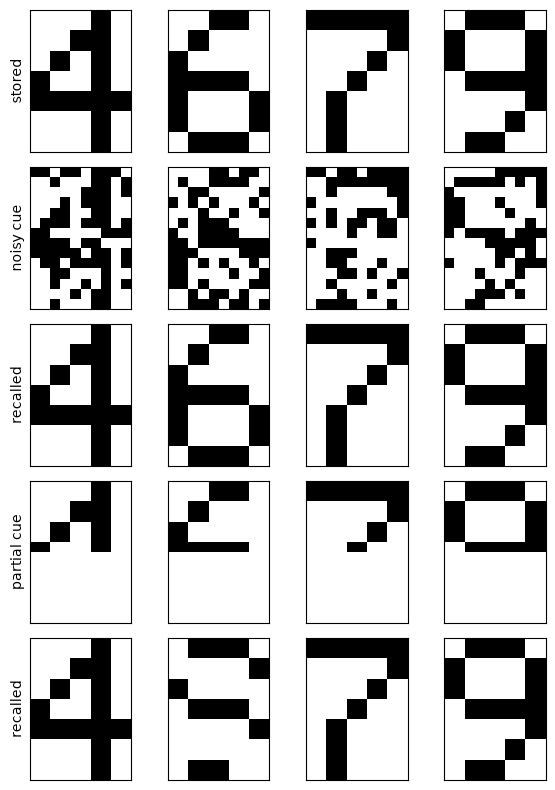

noisy cues recalled exactly:   [True, True, True, True]
partial cues recalled exactly: [True, False, True, True]


In [3]:
rng = np.random.default_rng(0)
noisy = np.array([corrupt(x, int(0.25 * net.K), rng) for x in X])
partial = X.copy().reshape(-1, *shape); partial[:, shape[0] // 2:, :] = -1; partial = partial.reshape(len(X), -1)
rec_noisy = np.array([net.recall(c, rng=rng) for c in noisy])
rec_partial = np.array([net.recall(c, rng=rng) for c in partial])
rows = [X, noisy, rec_noisy, partial, rec_partial]
names = ["stored", "noisy cue", "recalled", "partial cue", "recalled"]
fig, axes = plt.subplots(len(rows), len(X), figsize=(6, 8))
for r, (row, name) in enumerate(zip(rows, names)):
    for c in range(len(X)):
        axes[r, c].imshow(row[c].reshape(shape), cmap="gray_r", vmin=-1, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name)
plt.tight_layout(); plt.show()
print("noisy cues recalled exactly:  ", [np.array_equal(a, b) for a, b in zip(rec_noisy, X)])
print("partial cues recalled exactly:", [np.array_equal(a, b) for a, b in zip(rec_partial, X)])

Erasing half the image removes a lot of information, so a partial cue can occasionally settle into the wrong attractor (another digit, a mixture, or a spurious state) — content addressable memory works best when the cue is closer to the target than to any other memory.

## Energy never increases

The energy (Section 5.6, Eq 5.12)
$$E(\mathbf y) = -\sum_{i=1}^{K}\sum_{j=i+1}^{K} w_{ij}\,y_i y_j$$
cannot increase when a single unit is updated by Eq 5.4, so recall is a descent into an energy minimum (a stored memory, its complement, or a spurious state).

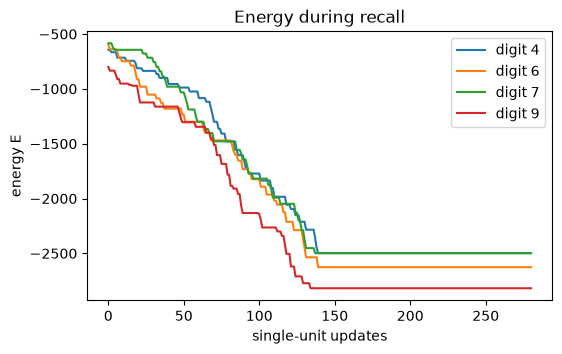

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for k, cue in enumerate(noisy):
    y, E = net.recall(cue, rng=np.random.default_rng(k), return_energies=True)
    assert np.all(np.diff(E) <= 1e-12)
    ax.plot(E, label=f"digit {chosen[k]}")
ax.set_xlabel("single-unit updates"); ax.set_ylabel("energy E"); ax.legend(); ax.set_title("Energy during recall")
plt.show()

## Capacity

With too many stored patterns the memories interfere and recall fails. For random patterns, the classical result (Amit, Gutfreund & Sompolinsky, 1985 — not derived in the book) is that about $0.14K$ patterns can be stored. We store $P$ random patterns in a net with $K=100$ units and measure the fraction recalled perfectly from the exact pattern and from a cue with 10 flipped bits.

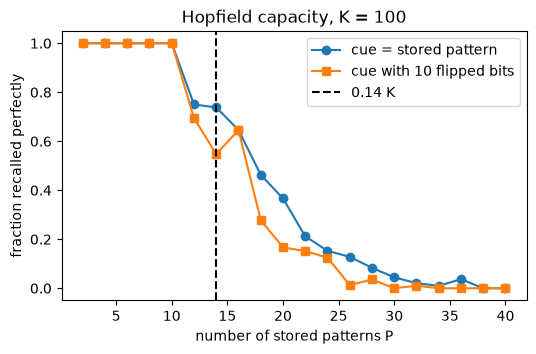

{2: 1.0, 4: 1.0, 6: 1.0, 8: 1.0, 10: 1.0, 12: 0.69, 14: 0.55, 16: 0.65, 18: 0.28, 20: 0.17, 22: 0.15, 24: 0.12, 26: 0.01, 28: 0.04, 30: 0.0, 32: 0.01, 34: 0.0, 36: 0.0, 38: 0.0, 40: 0.0}


In [5]:
K = 100
Ps = np.arange(2, 41, 2)
frac_clean = [recall_fraction(K, P, n_flips=0, seed=1, n_trials=3) for P in Ps]
frac_noisy = [recall_fraction(K, P, n_flips=10, seed=1, n_trials=3) for P in Ps]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(Ps, frac_clean, "o-", label="cue = stored pattern")
ax.plot(Ps, frac_noisy, "s-", label="cue with 10 flipped bits")
ax.axvline(0.14 * K, color="k", ls="--", label="0.14 K")
ax.set_xlabel("number of stored patterns P"); ax.set_ylabel("fraction recalled perfectly")
ax.legend(); ax.set_title(f"Hopfield capacity, K = {K}"); plt.show()
print(dict(zip(Ps.tolist(), np.round(frac_noisy, 2).tolist())))

Recall is perfect for small loads, and degrades rapidly once $P$ approaches $\approx0.14K$: the cross-talk between stored patterns turns them into unstable states and creates spurious minima.